Dataset Loaded Successfully by Gowtham pankaj

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  
              mpg   cylinders  displacement  horsepower       weight  \
count  398.000000  398.000000    398.000000  392.000000   398.000000   
mean    23.514573    5.454774    193.425879  104.469388  2970.424623   
std      7.81598

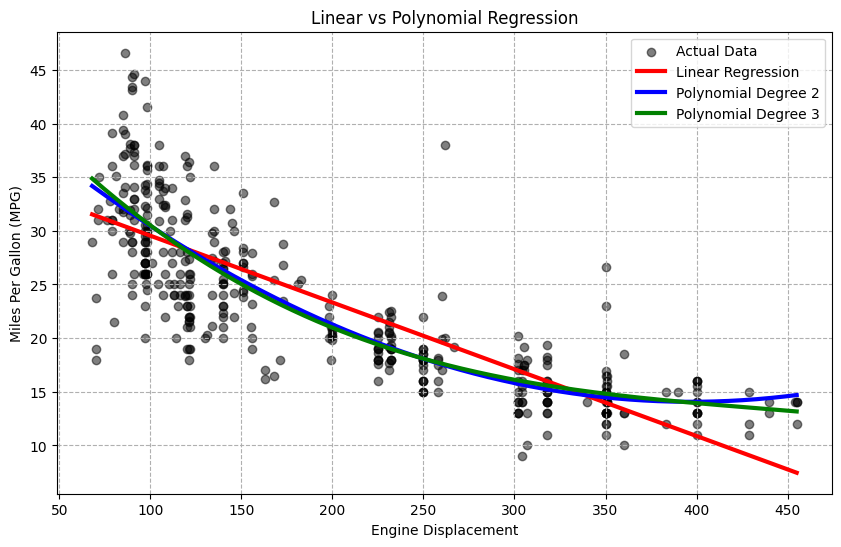

In [1]:
# ==========================================
# Import Libraries
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score


# ==========================================
# Load Dataset
# ==========================================

df = pd.read_csv("mpg.csv")

print("Dataset Loaded Successfully by Gowtham pankaj\n")

print(df.head())
print(df.describe())
print(df.shape)
print(df.dtypes)


# ==========================================
# Preprocessing
# ==========================================

print("\nMissing Values:")
print(df.isnull().sum())

df = df.dropna()
df = df.drop_duplicates()

df = df.drop(columns=["name"])

print("\nFinal Shape:", df.shape)


# ==========================================
# Feature and Target
# ==========================================

X = df[["displacement"]].values
y = df["mpg"].values


# ==========================================
# Train Test Split
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# ==========================================
# Models
# ==========================================

results = []

models = {}

# Linear Regression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)

results.append([
    "Linear Regression",
    mean_squared_error(y_test, y_pred),
    r2_score(y_test, y_pred)
])


# Polynomial Regression

for degree in [2, 3]:

    poly = PolynomialFeatures(
        degree=degree,
        include_bias=False
    )

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()

    model.fit(
        X_train_poly,
        y_train
    )

    y_pred = model.predict(
        X_test_poly
    )

    results.append([
        f"Polynomial Degree {degree}",
        mean_squared_error(y_test, y_pred),
        r2_score(y_test, y_pred)
    ])

    models[degree] = (poly, model)


# ==========================================
# Model Comparison
# ==========================================

result_df = pd.DataFrame(
    results,
    columns=["Model", "MSE", "R-Squared"]
)

print("\n========== MODEL COMPARISON ==========")
print(result_df)


# ==========================================
# Visualization
# ==========================================

X_curve = np.linspace(
    X.min(),
    X.max(),
    300
).reshape(-1,1)


plt.figure(figsize=(10,6))

plt.scatter(
    X,
    y,
    color="black",
    alpha=0.5,
    label="Actual Data"
)


# Linear curve

plt.plot(
    X_curve,
    linear_model.predict(X_curve),
    color="red",
    linewidth=3,
    label="Linear Regression"
)


# Polynomial curves

colors = {
    2: "blue",
    3: "green"
}


for degree in [2,3]:

    poly, model = models[degree]

    plt.plot(
        X_curve,
        model.predict(poly.transform(X_curve)),
        color=colors[degree],
        linewidth=3,
        label=f"Polynomial Degree {degree}"
    )


plt.title(
    "Linear vs Polynomial Regression"
)

plt.xlabel(
    "Engine Displacement"
)

plt.ylabel(
    "Miles Per Gallon (MPG)"
)

plt.grid(
    True,
    linestyle="--"
)

plt.legend()

plt.show()
